# 02 · Rebranding events, identifiers and event dates
> Run the notebooks in order (01 → 02 → 03 → 04 → 05 → 06 → 07 → 08) from inside the `code` folder. Raw inputs are in `data/` (described in notebook 01). Research questions:
> top of notebook 03.


This notebook turns the raw CRSP name history into the **event-level master dataset (Dataset A)** and finds
the **earliest public date** of each name change.

| Step | What happens |
|---|---|
| 1 | Load the WRDS extracts (described in notebook 01) |
| 2 | Listed-firm universe and **all** corporate name changes (RQ1 denominators) |
| 3 | Thematic rebranding events with the fixed keyword dictionary |
| 4 | **Identifier checks**: which ID is used for each merge, and whether it survives the name change / M&A |
| 5 | **SEC EDGAR dates**: first filing that names the new company name (proxy, 8-K, S-4, 10-Q, …) |
| 6 | **Other sources**: press releases, news, company websites, state records (searched by hand) |
| 7 | Event-date table: `effective_date`, `sec_edgar_date`, `other_source_date`, links, and `earliest_date` (earliest of all recorded dates, used in a sensitivity check) |
| 7b | **Event register**: verified `public_announcement_date`, confidence grade, release timing, deal type, flags for a second check |
| 8 | Check the event firms' daily stock data and save the processed files for notebook 03 |

**Event date used in the analysis.** The minimum of all recorded dates (`earliest_date`) can pick a date that
was **not public**: a board approval, a charter filing or a Nasdaq notice mentioned in a later filing. The
analysis therefore uses `public_announcement_date`: the
first date on which a **public document names this issuer's new name** (press release, 8-K/6-K by filing date,
proxy or information statement, registration statement, or a merger announcement that states the new name).
Each date has a confidence grade:

| Grade | Meaning | Used in |
|---|---|---|
| **A** | the document itself shows the new name and its publication date | main analysis |
| **B** | the new name is confirmed, but the date is weaker (newswire/listing date, filing header only, or the announcement coincides with the first day under the new name) | main analysis |
| **C** | no dated public announcement found, or only a month; the CRSP effective date is used | sensitivity check only |

The audit (one row per event, with a note) is in `data/event_dates/event_audit.csv`. Rows a teammate should
re-check are flagged `needs_second_check = 1`.

In [1]:
import re
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.random.seed(42)
random_state = 42
rng = np.random.default_rng(random_state)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rc("axes", titlesize=12, labelsize=11)

In [2]:
# ---- paths: run the notebooks from inside the code/ folder ----
base_dir = Path.cwd().parent                                  # project folder (the notebooks run from code/)
data_dir = base_dir / "data"                                  # raw input files (described in notebook 01)
wrds_dir = data_dir / "raw_data" / "wrds"                     # raw WRDS extracts
edgar_dir = data_dir / "raw_data" / "edgar_fts"               # EDGAR full-text search extract
event_dates_dir = data_dir / "event_dates"                    # hand-collected dates + SEC scan results (inputs)
event_dates_out_dir = base_dir / "event_dates"                # event-date table produced by notebook 02
processed_dir = base_dir / "processed"                        # intermediate tables passed between notebooks
output_dir = base_dir / "output"                              # result tables and figures
for folder in [processed_dir, output_dir, event_dates_out_dir, edgar_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- study design ----
study_start_year, study_end_year = 1990, 2025
eligible_exchanges = ["N", "A", "Q"]            # NYSE, NYSE American, Nasdaq
themes = ["Dot-com", "Blockchain", "AI"]         # Dot-com first = reference category in RQ3
theme_colors = {"Dot-com": "#2a78b5", "Blockchain": "#e08a1e", "AI": "#3a9e5f"}
wave_periods = {"Dot-com": (1995, 2002), "Blockchain": (2016, 2020), "AI": (2021, 2025)}
wave_reference_year = {"Dot-com": 1995, "Blockchain": 2017, "AI": 2022}   # Netscape IPO, Bitcoin boom, ChatGPT

### Keyword dictionary (fixed *before* looking at any returns)
* A name change is a **theme entry** when the new name matches a theme pattern and the old name does not.
* A keyword can only count once the technology exists. Dot-com counts from 1994 (the commercial web), Blockchain
  from 2009 (Bitcoin), and AI from 2015 (the deep-learning era). Before 2015, "AI" in a CRSP name is almost
  always a set of initials.
* Priority Blockchain → AI → Dot-com resolves names that match several themes (e.g. "WEB 3").
* Deliberately left out because of false positives: `NET` ("Health Net"), `DIGITAL`, `TECH`, `INTELLIGENCE`,
  `MACHINE`, `CHAIN` ("Supply Chain"), `COIN`.
* Excluded events: SPAC shells renamed to "… AI Acquisition Corp". No business has changed, only the shell's label.

In [3]:
legal_suffix = r"(?:INC|CORP|CORPORATION|CO|LTD|HOLDINGS?|HLDGS|GROUP|GRP)"
theme_patterns = {
    "Blockchain": [r"\bBLOCKCHAIN\b", r"\bBITCOIN\b", r"\bCRYPTO\w*", r"\bDIGITAL ASSETS?\b",
                   r"\bDISTRIBUTED LEDGER\b", r"\bWEB ?3\b", r"\bTOKEN\b"],
    "AI": [r"\bAI\b",
           r"(?<!\b[A-Z] )\bA I\b(?! [A-Z]\b)",       # CRSP's "A I" but not initials such as "L A I"
           r"\bARTIFICIAL INTEL\w*"],
    "Dot-com": [rf"\bCOM\b(?= {legal_suffix}\b|$)",     # CRSP's ".com": "XCELERA COM INC", "HOTELS COM"
                r"\bDOT ?COM\b", r"\bINTERNET\b", r"\bONLINE\b", r"\bWEB\b(?! ?3)",
                r"\bE ?COMMERCE\b", r"\bCYBER\b"],
}
theme_priority = ["Blockchain", "AI", "Dot-com"]
theme_first_year = {"Dot-com": 1994, "Blockchain": 2009, "AI": 2015}
spac_shell_pattern = r"\bACQ(?:UISITION)?\b"

# Event IDs to drop after manual review of SEC filings (fill in with a reason, before looking at returns)
manual_exclusions = {}   # e.g. {"permno_12345_2000-01-01": "name refers to communications, not .com"}

## Step 1: Load the WRDS extracts

In [4]:
def load_wrds_extracts():
    """
    Load the CRSP name histories and the CRSP-Compustat-CIK link table.

    Returns
    -------
    dict of pandas.DataFrame
        ``security``, ``issuer`` and ``cik_links``.
    """
    raw = {
        "security": pd.read_csv(wrds_dir / "crsp_security_info_history.csv.gz", low_memory=False),
        "issuer": pd.read_csv(wrds_dir / "crsp_issuer_info_history.csv.gz", low_memory=False),
        "cik_links": pd.read_csv(wrds_dir / "ccm_permno_gvkey_cik.csv.gz", dtype={"cik": str}),
    }
    for name, table in raw.items():
        print(f"  {name:<10} {table.shape[0]:>9,} rows x {table.shape[1]} cols")
    return raw


raw = load_wrds_extracts()
raw["issuer"].info()

  security     191,048 rows x 28 cols
  issuer       139,528 rows x 18 cols
  cik_links     33,324 rows x 6 cols
<class 'pandas.DataFrame'>
RangeIndex: 139528 entries, 0 to 139527
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   permco            139528 non-null  int64  
 1   issinfostartdt    139528 non-null  str    
 2   issinfoenddt      139528 non-null  str    
 3   issuerbegdt       139528 non-null  str    
 4   issuerenddt       139528 non-null  str    
 5   issuerhdrflg      139528 non-null  str    
 6   cnum              107155 non-null  str    
 7   issuernm          139528 non-null  str    
 8   securityrangecnt  139528 non-null  int64  
 9   securitytotalcnt  139528 non-null  int64  
 10  usincflg          139528 non-null  str    
 11  issuertype        139528 non-null  str    
 12  issuerstatustype  139528 non-null  str    
 13  siccd             110560 non-null  float64
 14  naics         

In [5]:
# Which security types and exchanges are in CRSP? (basis for the universe filter in Step 3)
for column in ["sharetype", "securitytype", "securitysubtype", "primaryexch"]:
    print(column, raw["security"][column].value_counts(dropna=False).to_dict())

sharetype {'NS': 148851, nan: 29833, 'AD': 6696, 'SB': 4094, 'UG': 1528, 'CE': 46}
securitytype {'EQTY': 136698, nan: 29833, 'FUND': 24436, 'DERV': 81}
securitysubtype {'COM': 136698, 'UNK': 29833, 'ETF': 17949, 'CEF': 6487, 'ATR': 81}
primaryexch {'Q': 91584, 'N': 39760, 'X': 31810, 'A': 14492, 'R': 10035, 'B': 3366, 'I': 1}


## Step 2: Data cleaning: listed-firm universe and all name changes
1. **Eligible securities:** ordinary common stock (share type NS, EQTY/COM) whose primary exchange is NYSE,
   NYSE American or Nasdaq.
2. **Listed firms per year (denominator):** a company (PERMCO) counts in year *t* if one of its eligible
   security intervals overlaps year *t*.
3. **All corporate name changes:** sort the issuer name history by company and date and compare
   OldName<sub>t</sub> = Name<sub>t−1</sub> with NewName<sub>t</sub>. A change counts only when the *core* name differs,
   i.e. not just "INC" → "INC NEW", and only when the company has an eligible listed security on that date.
   No buzzword filter is applied here; this is the master name-change dataset and the denominator of the
   thematic share.

eligible security intervals: 125,348; name changes 1990-2025: 6,772


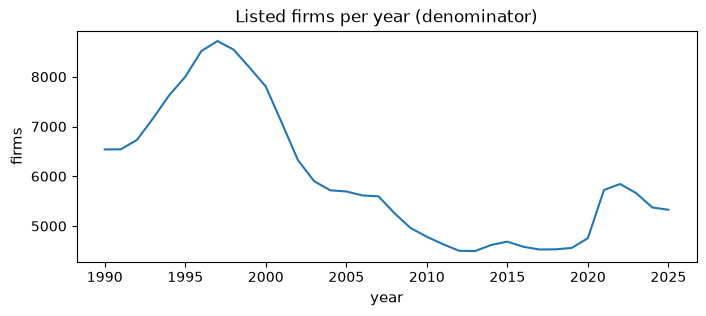

In [6]:
def clean_name(series):
    """
    Upper-case company names and collapse repeated whitespace.

    Parameters
    ----------
    series : pandas.Series

    Returns
    -------
    pandas.Series
    """
    return series.fillna("").astype(str).str.upper().str.replace(r"\s+", " ", regex=True).str.strip()


def core_name(series):
    """
    Remove legal suffixes and CRSP markers ("NEW", "(LAST KNOWN)") to compare the substance of two names.

    Parameters
    ----------
    series : pandas.Series
        Cleaned names.

    Returns
    -------
    pandas.Series
    """
    pattern = r"\b(INC|CORP|CORPORATION|CO|LTD|LIMITED|PLC|LLC|LP|NEW|DEL|THE|\(LAST KNOWN\))\b"
    return series.str.replace(pattern, "", regex=True).str.replace(r"[^A-Z0-9 ]", "", regex=True) \
                 .str.replace(r"\s+", " ", regex=True).str.strip()


def build_eligible_securities(security):
    """
    Keep CRSP security-information intervals of listed ordinary common stock.

    Parameters
    ----------
    security : pandas.DataFrame
        CRSP ``stksecurityinfohist`` extract.

    Returns
    -------
    pandas.DataFrame
        Eligible intervals with ``start_date`` and ``end_date``.
    """
    eligible = security[(security["sharetype"] == "NS") & (security["securitytype"] == "EQTY")
                        & (security["securitysubtype"] == "COM")
                        & security["primaryexch"].isin(eligible_exchanges)].copy()
    eligible["start_date"] = pd.to_datetime(eligible["secinfostartdt"])
    eligible["end_date"] = pd.to_datetime(eligible["secinfoenddt"])
    return eligible


def build_listed_firm_counts(eligible):
    """
    Count distinct listed companies (PERMCO) per calendar year.

    Parameters
    ----------
    eligible : pandas.DataFrame
        Output of :func:`build_eligible_securities`.

    Returns
    -------
    pandas.DataFrame
        ``year`` and ``listed_firms`` for 1990-2025.
    """
    first = eligible["start_date"].dt.year.clip(lower=study_start_year)
    last = eligible["end_date"].dt.year.clip(upper=study_end_year)
    keep = first <= last
    firm_years = pd.DataFrame({
        "permco": eligible.loc[keep, "permco"].to_numpy(),
        "year": [list(range(a, b + 1)) for a, b in zip(first[keep], last[keep])],
    }).explode("year").drop_duplicates()
    listed = firm_years.groupby("year").size().rename("listed_firms").reset_index()
    listed["year"] = listed["year"].astype(int)
    return listed


def build_all_name_changes(issuer, eligible):
    """
    Turn the issuer name history into company-level name-change events.

    Parameters
    ----------
    issuer : pandas.DataFrame
        CRSP ``stkissuerinfohist`` extract.
    eligible : pandas.DataFrame
        Eligible security intervals.

    Returns
    -------
    pandas.DataFrame
        One row per name change of a listed company: ``permco``, ``permno`` (the eligible security on
        the change date), ``change_date``, ``old_name``, ``new_name``, ``year``, ``siccd``.
    """
    names = issuer[["permco", "issinfostartdt", "issuernm", "siccd"]].copy()
    names["change_date"] = pd.to_datetime(names["issinfostartdt"])
    names["new_name"] = clean_name(names["issuernm"])
    names = names.sort_values(["permco", "change_date"])
    names["old_name"] = names.groupby("permco")["new_name"].shift(1)
    changed = names["old_name"].notna() & (core_name(names["old_name"].fillna("")) != core_name(names["new_name"]))
    changes = names[changed & names["change_date"].dt.year.between(study_start_year, study_end_year)]

    # keep companies with an eligible listed security on the change date (first PERMNO if several)
    candidates = changes[["permco", "change_date"]].merge(
        eligible[["permco", "permno", "start_date", "end_date"]], on="permco")
    candidates = candidates[(candidates["start_date"] <= candidates["change_date"])
                            & (candidates["end_date"] >= candidates["change_date"])]
    candidates = candidates.sort_values("permno").drop_duplicates(["permco", "change_date"])
    changes = changes.merge(candidates[["permco", "change_date", "permno"]], on=["permco", "change_date"])
    changes["year"] = changes["change_date"].dt.year
    return changes[["permco", "permno", "change_date", "year", "old_name", "new_name", "siccd"]] \
        .reset_index(drop=True)


eligible = build_eligible_securities(raw["security"])
listed = build_listed_firm_counts(eligible)
all_changes = build_all_name_changes(raw["issuer"], eligible)
print(f"eligible security intervals: {len(eligible):,}; name changes 1990-2025: {len(all_changes):,}")
listed.set_index("year")["listed_firms"].plot(figsize=(8, 3), title="Listed firms per year (denominator)")
plt.ylabel("firms")
plt.show()

## Step 3: Thematic rebranding events
1. Apply the keyword dictionary to every name change and keep **theme entries**, where the keyword is in the
   new name but not the old one.
2. Drop SPAC-shell renames and any `manual_exclusions`.
3. Flag **former SPACs** (old name is an "Acquisition" shell or SIC 6799) and events inside the theme's wave
   period. This flag is only a **firm characteristic**: a firm that merged with a SPAC years before renaming
   (e.g. Sarcos 2021 → Palladyne AI 2024) is a former SPAC, but its rename is not a de-SPAC closing; whether the rename coincides with a SPAC deal is the `deal_type` in Step 7b.

In [7]:
def match_theme(name, theme):
    """
    Check whether a company name contains one of the theme's keywords.

    Parameters
    ----------
    name : str
        Cleaned company name.
    theme : str
        "Dot-com", "Blockchain" or "AI".

    Returns
    -------
    bool
    """
    return any(re.search(pattern, name) for pattern in theme_patterns[theme])


def classify_name_changes(all_changes):
    """
    Label each name change with the theme it newly introduces (theme entry), if any.

    Parameters
    ----------
    all_changes : pandas.DataFrame
        Output of :func:`build_all_name_changes`.

    Returns
    -------
    pandas.Series
        Theme or ``None`` for every name change.
    """
    labels = []
    for old_name, new_name, year in zip(all_changes["old_name"], all_changes["new_name"], all_changes["year"]):
        label = None
        for theme in theme_priority:
            if (year >= theme_first_year[theme] and match_theme(new_name, theme)
                    and not match_theme(old_name, theme)):
                label = theme
                break
        labels.append(label)
    return pd.Series(labels, index=all_changes.index)


def build_events(all_changes):
    """
    Build the event-level master dataset (Dataset A).

    Parameters
    ----------
    all_changes : pandas.DataFrame
        All name changes of listed companies.

    Returns
    -------
    events : pandas.DataFrame
        Final thematic rebranding events.
    excluded : pandas.DataFrame
        Theme entries removed by the exclusion rules, with the reason.
    """
    changes = all_changes.assign(theme=classify_name_changes(all_changes))
    candidates = changes[changes["theme"].notna()].rename(columns={"change_date": "effective_date"}).copy()
    candidates["event_key"] = ("permno_" + candidates["permno"].astype(str) + "_"
                               + candidates["effective_date"].dt.strftime("%Y-%m-%d"))
    candidates["exclusion_reason"] = ""
    candidates.loc[candidates["new_name"].str.contains(spac_shell_pattern, regex=True),
                   "exclusion_reason"] = "SPAC shell renamed (no operating business)"
    for key, reason in manual_exclusions.items():
        candidates.loc[candidates["event_key"] == key, "exclusion_reason"] = reason
    excluded = candidates[candidates["exclusion_reason"] != ""]
    events = candidates[candidates["exclusion_reason"] == ""].drop(columns="exclusion_reason")

    events["former_spac"] = (events["old_name"].str.contains(spac_shell_pattern, regex=True)
                             | (events["siccd"] == 6799)).astype(int)
    events["in_wave_period"] = [int(wave_periods[t][0] <= y <= wave_periods[t][1])
                                for t, y in zip(events["theme"], events["effective_date"].dt.year)]
    events = events.sort_values(["effective_date", "permno"]).reset_index(drop=True)
    events.insert(0, "event_id", range(1, len(events) + 1))
    return events, excluded



events, excluded_events = build_events(all_changes)
print("events per theme:", events["theme"].value_counts().reindex(themes).to_dict())
print("excluded:", excluded_events[["new_name", "exclusion_reason"]].to_dict("records"))
events[["event_id", "theme", "permno", "permco", "effective_date", "old_name", "new_name", "former_spac", "in_wave_period"]]

events per theme: {'Dot-com': 79, 'Blockchain': 4, 'AI': 14}
excluded: [{'new_name': 'INVESTCORP AI ACQUISITION CORP', 'exclusion_reason': 'SPAC shell renamed (no operating business)'}]


,event_id,theme,permno,permco,effective_date,old_name,new_name,former_spac,in_wave_period
0,1,Dot-com,11964,9805,1998-02-26,EGGHEAD INC,EGGHEAD COM INC,0,1
1,2,Dot-com,76236,10490,1998-04-20,LASERMASTER TECHNOLOGIES INC,VIRTUALFUND COM INC,0,1
2,3,Dot-com,80975,13378,1998-07-07,ENTERACTIVE INC,CORNERSTONE INTERNET SOLUTNS CO,0,1
3,4,Dot-com,85979,16078,1998-08-10,FIRST VIRTUAL CORP,F V C COM INC,0,1
4,5,Dot-com,81212,13509,1998-09-25,INFOSAFE SYSTEMS INC,INTERNET COMMERCE CORP,0,1
...,...,...,...,...,...,...,...,...,...
92,93,Blockchain,17326,56234,2025-09-03,GRYPHON DIGITAL MINING INC,AMERICAN BITCOIN CORP,0,0
93,94,AI,23993,59540,2025-09-25,ARES ACQUISITION CORP II,KODIAK AI INC,1,1
94,95,AI,19846,57360,2025-10-07,SIYATA MOBILE INC,CORE AI HOLDINGS INC,0,1
95,96,Dot-com,14532,54780,2025-12-02,A MARK PRECIOUS METALS INC,GOLD COM INC,0,0


## Step 4: Identifier checks
Name changes and M&A change many identifiers, so each merge uses the ID that stays fixed through them:

| Merge | Identifier | Why |
|---|---|---|
| Name history → events → daily returns | **PERMNO** / **PERMCO** (CRSP) | Permanent. They do not change with the name, ticker or CUSIP. A **CUSIP usually changes with a name change** and tickers change too, so neither is used as a key. |
| CRSP → Compustat | **GVKEY via the CCM link valid on the fiscal-year-end date** | De-SPACs link to the SPAC shell's GVKEY before the merger and to the operating company after. The date-valid link picks the right one. |
| Events → SEC EDGAR | **All CIKs linked to the PERMNO**, plus a manual CIK where Compustat holds only the successor's CIK | In reverse mergers and de-SPACs the SEC registrant can be the shell, or the CIK may belong to a later re-listing (e.g. Bankrate 2011 instead of iLife.com 1999). |
| Events → hand-collected dates | **PERMNO + effective date (±30 days)** | Names are spelled differently across sources. |

The checks below flag events where the PERMNO does not trade continuously around the event, or where no CIK is
available.

In [8]:
def check_identifiers(events, security, cik_links):
    """
    Check, per event, that the identifiers used in later merges are valid around the event.

    Parameters
    ----------
    events : pandas.DataFrame
        Event table (PERMNO, PERMCO, effective date).
    security : pandas.DataFrame
        CRSP security information history.
    cik_links : pandas.DataFrame
        PERMNO-GVKEY-CIK links with validity dates.

    Returns
    -------
    pandas.DataFrame
        One row per event: CUSIP / ticker before and after (to show they change), whether the PERMNO is
        listed on both sides of the event, the CCM-linked GVKEYs and CIKs.
    """
    sec = security.assign(start=pd.to_datetime(security["secinfostartdt"]),
                          end=pd.to_datetime(security["secinfoenddt"]))
    links = cik_links.assign(link_start=pd.to_datetime(cik_links["linkdt"]),
                             link_end=pd.to_datetime(cik_links["linkenddt"]).fillna(pd.Timestamp("2099-12-31")))
    rows = []
    for event in events.itertuples():
        history = sec[sec["permno"] == event.permno].sort_values("start")
        before = history[history["start"] < event.effective_date].tail(1)
        after = history[history["start"] >= event.effective_date].head(1)
        firm_links = links[links["permno"] == event.permno]
        valid_link = firm_links[(firm_links["link_start"] <= event.effective_date)
                                & (firm_links["link_end"] >= event.effective_date)]
        rows.append({
            "event_id": event.event_id, "permno": event.permno,
            "cusip_before": before["cusip"].iloc[0] if len(before) else None,
            "cusip_after": after["cusip"].iloc[0] if len(after) else None,
            "ticker_before": before["ticker"].iloc[0] if len(before) else None,
            "ticker_after": after["ticker"].iloc[0] if len(after) else None,
            "listed_before_and_after": bool(len(before) and len(after)),
            "gvkeys": ",".join(sorted(firm_links["gvkey"].astype(str).unique())),
            "gvkey_valid_on_event_date": ",".join(sorted(valid_link["gvkey"].astype(str).unique())),
            "ciks": ",".join(sorted(firm_links["cik"].dropna().unique())),
        })
    checks = pd.DataFrame(rows)
    checks["cusip_changed"] = checks["cusip_before"] != checks["cusip_after"]
    checks["ticker_changed"] = checks["ticker_before"] != checks["ticker_after"]
    return checks


identifier_checks = check_identifiers(events, raw["security"], raw["cik_links"])
print(f"CUSIP changed at the name change: {identifier_checks['cusip_changed'].mean():.0%} of events")
print(f"ticker changed at the name change: {identifier_checks['ticker_changed'].mean():.0%} of events")
print(f"PERMNO listed before and after: {identifier_checks['listed_before_and_after'].mean():.0%}")
print(f"events with >1 GVKEY over time (e.g. SPAC shell -> operating company): "
      f"{(identifier_checks['gvkeys'].str.count(',') > 0).sum()}")
print(f"events without any CIK in Compustat: {(identifier_checks['ciks'] == '').sum()}")
identifier_checks[~identifier_checks["listed_before_and_after"] | (identifier_checks["ciks"] == "")]

CUSIP changed at the name change: 82% of events
ticker changed at the name change: 63% of events
PERMNO listed before and after: 99%
events with >1 GVKEY over time (e.g. SPAC shell -> operating company): 7
events without any CIK in Compustat: 5


,event_id,permno,cusip_before,cusip_after,ticker_before,ticker_after,listed_before_and_after,gvkeys,gvkey_valid_on_event_date,ciks,cusip_changed,ticker_changed
3,4,85979,33748510,30266P10,FVCX,FVCX,True,110100,110100,,True,False
25,26,87348,NaN,86149C10,NaN,STOK,False,63665,63665,0001001136,True,True
42,43,83321,93490010,10526110,WARP,BRND,True,,,,True,True
43,44,80265,74268340,42248Q10,PRCT,HVDC,True,29708,29708,,True,True
56,57,84237,62872L10,18682E10,NAMC,CLIK,True,63979,63979,,True,True
57,58,86831,46033G10,16945710,ISMT,ISMT,True,119955,119955,,True,False


## Step 5: SEC EDGAR dates
For each event we read the company's filings dated from 450 days before to 15 days after the CRSP effective
date, **oldest first**. Forms: proxy and information statements, 8-K, S-4/F-4, 425, 10-Q/10-K, 6-K/20-F,
registration statements. The **first filing that names the new company name** gives `sec_edgar_date`.

A mention only counts when:
* it is not a web address (`www.egghead.com` in 1997 is the website, not the company);
* it is next to a legal suffix ("Xcelera.com, Inc.") or to name-change wording ("change the name of the Company
  to …", "will be renamed …", "formerly known as …").

The CRSP name is turned into a pattern that allows the punctuation CRSP removed, so `XCELERA COM` matches
"Xcelera.com". Names made only of common words ("INTERNET COMMERCE CORP") need the legal suffix.

**Manual review.** Every match was read. Fifteen first-pass matches named a **subsidiary** or a **merger
target** that already carried the name (e.g. "e-Net's wholly owned subsidiary ZeroPlus.com"), or a **website**.
Those events were re-scanned with a strict rule: the name must follow name-change wording, and subsidiary
mentions are skipped. The remaining review decisions are listed in `sec_review`.

The scan was run on 2026-10-15 with these rules; its results are saved in `data/event_dates/sec_work/` and loaded below.

In [9]:
sec_work_dir = event_dates_dir / "sec_work"                  # saved SEC EDGAR scan results (2026-10-15)

In [10]:
# Review decisions after reading every matched snippet (see markdown above)
strict_rescan_ids = {23, 25, 34, 40, 42, 47, 52, 55, 56, 57, 59, 64, 69, 76, 84}   # first-pass match was a
#   subsidiary / merger target / website -> strict re-scan
sec_review = {
    25: "strict match is a merger subsidiary renamed popmail.com, not the parent -> no SEC date",
    69: "strict match is a subsidiary formerly named Web.com -> no SEC scan date (source in the event-date audit)",
}
sec_manual = {   # found by web search and checked on EDGAR (filing date from data.sec.gov)
    63: {"sec_edgar_date": "2002-04-25", "sec_form": "8-K",
         "sec_edgar_source": "https://www.sec.gov/Archives/edgar/data/1098322/000095013402004148/d96284e8-k.htm",
         "sec_snippet": "8-K: Hotel Reservations Network changed its corporate name to Hotels.com (press release 25 Apr 2002)"},
}


def load_sec_scan(events):
    """
    Load the saved SEC EDGAR scan results (2026-10-15) and apply the review decisions.

    Parameters
    ----------
    events : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        One row per event with the reviewed SEC date, form, link and snippet.
    """
    saved = json.loads((sec_work_dir / "sec_scan_results.json").read_text())
    first = pd.DataFrame(saved["scan1"] + saved["scan2"]).drop_duplicates("event_id", keep="last")
    strict = pd.DataFrame(json.loads((sec_work_dir / "sec_scan_results_strict.json").read_text()))
    scan = pd.concat([first[~first["event_id"].isin(strict_rescan_ids)], strict], ignore_index=True)
    scan = scan.rename(columns={"sec_date": "sec_edgar_date", "form": "sec_form", "url": "sec_edgar_source",
                                "snippet": "sec_snippet"})
    scan = events[["event_id"]].merge(scan, on="event_id", how="left")
    scan["sec_review_note"] = ""
    for event_id, note in sec_review.items():
        columns = ["sec_edgar_date", "sec_form", "sec_edgar_source", "sec_snippet"]
        scan.loc[scan["event_id"] == event_id, columns] = None
        scan.loc[scan["event_id"] == event_id, "sec_review_note"] = note
    for event_id, values in sec_manual.items():
        for column, value in values.items():
            scan.loc[scan["event_id"] == event_id, column] = value
        scan.loc[scan["event_id"] == event_id, "sec_review_note"] = "added manually (web search, verified on EDGAR)"
    return scan[["event_id", "sec_edgar_date", "sec_form", "sec_edgar_source", "sec_snippet", "sec_review_note"]]


sec_scan = load_sec_scan(events)
print(f"events with an SEC EDGAR date: {sec_scan['sec_edgar_date'].notna().sum()} of {len(events)}")
sec_scan.head(10)

events with an SEC EDGAR date: 83 of 97


,event_id,sec_edgar_date,sec_form,sec_edgar_source,sec_snippet,sec_review_note
0,1,1998-01-28,8-K,https://www.sec.gov/Archives/edgar/data/832320...,"922-7031 (Registrant's telephone number, incl...",
1,2,1998-02-26,DEF 14A,https://www.sec.gov/Archives/edgar/data/857470...,"m, or until his successor has been duly electe...",
2,3,1998-05-20,PRE 14A,https://www.sec.gov/Archives/edgar/data/929648...,Company's Common Stock; 4. To approve an amen...,
3,4,1998-08-11,10-Q,https://www.sec.gov/Archives/edgar/data/920317...,ION TYPE: 10-Q PUBLIC DOCUMENT COUNT: 5 CONFOR...,
4,5,1998-07-02,PRE 14C,https://www.sec.gov/Archives/edgar/data/894738...,ation has lapsed (iii) increase to the number ...,
5,6,1998-11-16,10-Q,https://www.sec.gov/Archives/edgar/data/948545...,mmence employment with the Company in December...,
6,7,1998-11-16,10-Q,https://www.sec.gov/Archives/edgar/data/106053...,ing part of the Company's Registration Stateme...,
7,8,NaN,NaN,NaN,NaN,
8,9,1999-02-08,8-K,https://www.sec.gov/Archives/edgar/data/872901...,UMENT COUNT: 2 CONFORMED PERIOD OF REPORT: 199...,
9,10,NaN,NaN,NaN,NaN,


## Step 6: Other sources (press releases, news, company websites, state records)
We searched the web by hand for the events: company press releases (PR Newswire, Business Wire, company
newsrooms), US, local and global news archives, trade press, company websites, and government records (state
corporation filings, USPTO trademark filings). Each result was opened to confirm its date. The findings are in
`data/event_dates/sec_work/other_sources_log.csv`, with a note per event, including when nothing was found or only
a month/year was available. In those cases the date is left blank, because a month alone cannot place day 0.

All sources in this project were collected by us: our own SEC EDGAR scan (Step 5), this web-search log, and, for
29 events whose announcement was confirmed directly in SEC filings or newswires during the event-date audit, the source
link and passage recorded in the audit file (Step 7b). No externally supplied event table is used.

In [11]:
def load_other_sources(events):
    """
    Load our own web-search log of press, news and other non-SEC sources.

    Parameters
    ----------
    events : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        ``event_id``, ``other_source_date``, ``other_source_link``, ``other_source_note``, ``other_source_origin``.
    """
    log = pd.read_csv(sec_work_dir / "other_sources_log.csv")
    log["other_source_date"] = pd.to_datetime(log["other_source_date"], errors="coerce")
    log = log[log["event_id"].isin(events["event_id"])]
    return log.assign(other_source_origin="web search 2026-10-15")


other_sources = load_other_sources(events)
print(f"events with a dated other source: {other_sources['other_source_date'].notna().sum()} of {len(events)}")
other_sources[other_sources["other_source_date"].notna()].head(10)

events with a dated other source: 22 of 97


,event_id,other_source_date,other_source_link,other_source_note,other_source_origin
0,1,1998-01-28,https://internetnews.com/small-business/egghea...,InternetNews 28 Jan 1998: Egghead to shift to ...,web search 2026-10-15
3,6,1998-11-16,https://www.proquest.com/docview/216954433,trade journal abstract: Tel-Save Holdings chan...,web search 2026-10-15
4,7,1998-07-10,https://trademarks.justia.com/owners/beyond-co...,USPTO trademark application BEYOND.COM filed 1...,web search 2026-10-15
5,8,1998-12-22,https://nexttv.com/news/cellularvision-changes...,Broadcasting & Cable: CellularVision USA annou...,web search 2026-10-15
6,9,1999-02-08,https://g.foolcdn.com/foolaudio/transcripts/19...,Motley Fool StockTalk interview (Aug 1999): co...,web search 2026-10-15
7,10,1999-03-31,https://ecommercetimes.com/?p=167592,E-Commerce Times 31 Mar 1999: company just cha...,web search 2026-10-15
17,20,1999-07-19,https://www.proquest.com/docview/449618089,PR Newswire 19 Jul 1999 (ProQuest): 7th Street...,web search 2026-10-15
18,21,1999-06-02,https://www.writerswrite.com/goodnoise-becomes...,Press release 2 Jun 1999: GoodNoise changing i...,web search 2026-10-15
30,34,1999-09-28,https://www.cbssports.com/info/aboutus/press/1...,Company press release 28 Sep 1999: SportsLine ...,web search 2026-10-15
33,38,1999-12-17,https://www.writerswrite.com/intelligent-life-...,Press release 17 Dec 1999: Intelligent Life Co...,web search 2026-10-15


## Step 7: Event-date table and the `earliest_date` rule
$$earliest\_date_i = \min\big(effective\_date_i,\; sec\_edgar\_date_i,\; other\_source\_date_i\big)$$
This is the **earliest of all recorded dates**, computed from our own SEC scan and web search. It is used only as
an alternative date rule (sensitivity row 10 in notebook 07); the analysis uses the audited public date of Step 7b. The
table is saved as `event_dates/event_dates_97.xlsx`.

In [12]:
def build_event_date_table(events, sec_scan, other_sources):
    """
    Assemble the event-date table and compute ``earliest_date`` (earliest of all recorded dates) from our own sources.

    Parameters
    ----------
    events, sec_scan, other_sources : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        One row per event with all dates, links, notes, ``earliest_date`` and ``earliest_date_source``.
    """
    table = events[["event_id", "theme", "permno", "permco", "old_name", "new_name", "effective_date"]] \
        .merge(sec_scan, on="event_id", how="left").merge(other_sources, on="event_id", how="left")
    table["sec_edgar_date"] = pd.to_datetime(table["sec_edgar_date"])
    table["sec_edgar_origin"] = np.where(table["sec_edgar_date"].notna(), "SEC scan", "")
    candidates = table[["effective_date", "sec_edgar_date", "other_source_date"]]
    table["earliest_date"] = candidates.min(axis=1)
    table["earliest_date_source"] = candidates.idxmin(axis=1).str.replace("_date", "")
    table["days_earliest_to_effective"] = (table["effective_date"] - table["earliest_date"]).dt.days
    columns = ["event_id", "theme", "permno", "permco", "old_name", "new_name", "effective_date",
               "sec_edgar_date", "other_source_date", "sec_edgar_source", "other_source_link", "earliest_date",
               "earliest_date_source", "days_earliest_to_effective", "sec_form", "sec_edgar_origin",
               "sec_snippet", "sec_review_note", "other_source_origin", "other_source_note"]
    return table[columns].sort_values("event_id").reset_index(drop=True)


event_dates = build_event_date_table(events, sec_scan, other_sources)
event_dates.to_excel(event_dates_out_dir / "event_dates_97.xlsx", index=False)
print("earliest date comes from:", event_dates["earliest_date_source"].value_counts().to_dict())
print("median days between earliest public date and CRSP effective date:",
      event_dates["days_earliest_to_effective"].median())
event_dates[["event_id", "theme", "new_name", "effective_date", "sec_edgar_date", "other_source_date",
             "earliest_date", "earliest_date_source"]]

earliest date comes from: {'sec_edgar': 67, 'effective': 21, 'other_source': 9}
median days between earliest public date and CRSP effective date: 32.0


,event_id,theme,new_name,effective_date,sec_edgar_date,other_source_date,earliest_date,earliest_date_source
0,1,Dot-com,EGGHEAD COM INC,1998-02-26,1998-01-28,1998-01-28,1998-01-28,sec_edgar
1,2,Dot-com,VIRTUALFUND COM INC,1998-04-20,1998-02-26,NaT,1998-02-26,sec_edgar
2,3,Dot-com,CORNERSTONE INTERNET SOLUTNS CO,1998-07-07,1998-05-20,NaT,1998-05-20,sec_edgar
3,4,Dot-com,F V C COM INC,1998-08-10,1998-08-11,NaT,1998-08-10,effective
4,5,Dot-com,INTERNET COMMERCE CORP,1998-09-25,1998-07-02,NaT,1998-07-02,sec_edgar
...,...,...,...,...,...,...,...,...
92,93,Blockchain,AMERICAN BITCOIN CORP,2025-09-03,2025-05-12,NaT,2025-05-12,sec_edgar
93,94,AI,KODIAK AI INC,2025-09-25,2025-04-14,NaT,2025-04-14,sec_edgar
94,95,AI,CORE AI HOLDINGS INC,2025-10-07,2025-10-06,NaT,2025-10-06,sec_edgar
95,96,Dot-com,GOLD COM INC,2025-12-02,2025-11-07,2025-11-06,2025-11-06,other_source


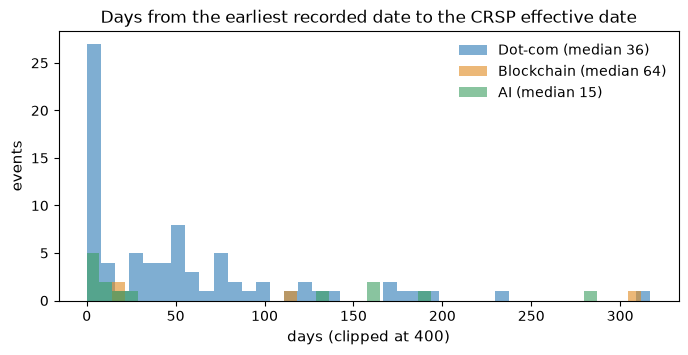

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for theme in themes:
    gaps = event_dates.loc[event_dates["theme"] == theme, "days_earliest_to_effective"]
    ax.hist(gaps.clip(upper=400), bins=40, alpha=0.6, color=theme_colors[theme], label=f"{theme} (median {gaps.median():.0f})")
ax.set(title="Days from the earliest recorded date to the CRSP effective date", xlabel="days (clipped at 400)", ylabel="events")
ax.legend(frameon=False)
plt.show()

## Step 7b: Event register (verified public dates, grades, deal types)
**Audit procedure.** Every one of the 97 events was re-read against its SEC snippet, press/news note and links,
before looking at any returns. For each event the audit records:
* `public_announcement_date`: the first date a public document names the new name. Not counted: board-approval
  or charter-filing dates quoted in a later filing, the 8-K cover's "date of earliest event reported", unrelated
  items such as a Nasdaq notice, a merger announcement that does not state the new name, and trademark filings.
  Three dates need particular care: MultiSensor AI 12 Feb 2024 (not 6 Feb, the board
  approval), Palladyne AI 18 Mar 2024 (not 11 Mar, a Nasdaq notice), Core AI 3 Oct 2025 (the Feb 2025 exhibit
  does not name Core AI).
* `date_confidence` A / B / C (see the top of this notebook).
* `announcement_timing`: `after_close` when the source shows the news came after 16:00 ET (day 0 then moves to
  the next session), `before_open`, or `unknown` (day 0 = that date; notebook 07 re-runs with day 0 one session
  later).
* `deal_type`, coded from the **same announcement** (the document that first names the new name):

| Code | Deal type | Role in the analysis |
|---|---|---|
| a | cosmetic / standalone rename (the business continues; may include a stated shift of emphasis) | main sample |
| b | business pivot or restructuring announced with the rename (new line of business, divestiture) | main sample |
| c | rename with a merger, acquisition or reverse merger | reported separately |
| d | rename at a SPAC business combination (de-SPAC) | reported separately |
| e | rename announced together with other material news (earnings, reverse split, exchange transfer) | reported separately |

* `former_spac` (Step 3) stays a **firm characteristic**: a firm that merged with a SPAC years ago and renames
  later is coded a or b, not d.
* `needs_second_check = 1` marks rows a teammate should verify independently (ambiguous date, filing text not
  read, deal not verified). They stay in the analysis with their current code; notebook 07 shows the results
  without them.

**Main (primary) sample** = grade A or B, inside the wave period (by announcement year), deal type a or b.
Grade-C events and deal types c–e stay in the register and in the RQ1 counts, and appear in the sensitivity tables.

In [14]:
deal_type_labels = {"a": "cosmetic / standalone rename", "b": "business pivot or restructuring",
                    "c": "merger, acquisition or reverse merger", "d": "SPAC business combination (de-SPAC)",
                    "e": "other material news in the same announcement"}


def describe_source(row):
    """
    Return the source type, link and supporting passage of an event's public announcement date.

    Parameters
    ----------
    row : namedtuple
        One row of the merged event-date table and audit.

    Returns
    -------
    tuple of str
        (source type, source link, supporting passage)
    """
    date = row.public_announcement_date
    if pd.isna(date):
        return "none: CRSP effective date used", None, row.audit_note
    if isinstance(row.source_url, str):              # source located and read during the event-date audit
        kind = "SEC filing (read in the audit)" if "sec.gov" in row.source_url else "press release / news (audit)"
        return kind, row.source_url, row.source_note
    if isinstance(row.source_note, str):             # date stated inside the filing found by our scan
        return "SEC filing (date stated in the document)", row.sec_edgar_source, row.sec_snippet
    if pd.notna(row.sec_edgar_date) and date == row.sec_edgar_date:
        form = f" ({row.sec_form})" if isinstance(row.sec_form, str) else ""
        return f"SEC filing{form}", row.sec_edgar_source, row.sec_snippet
    if pd.notna(row.other_source_date) and date == row.other_source_date:
        return "press release / news", row.other_source_link, row.other_source_note
    if date == row.effective_date:
        return "first trading day under the new name", None, row.audit_note
    return "see audit note", row.sec_edgar_source, row.audit_note


def build_event_register(event_dates, events, audit):
    """
    Combine the event-date table with the event-date audit into the event register.

    Parameters
    ----------
    event_dates : pandas.DataFrame
        Output of :func:`build_event_date_table` (incl. ``earliest_date``).
    events : pandas.DataFrame
        Event table with ``former_spac``.
    audit : pandas.DataFrame
        ``event_audit.csv``.

    Returns
    -------
    pandas.DataFrame
        One row per event with the ``event_date``, its source, grade, timing, deal type and sample flags.
    """
    register = event_dates.merge(events[["event_id", "former_spac", "siccd"]], on="event_id") \
                          .merge(audit, on="event_id", how="left", validate="one_to_one")
    register["public_announcement_date"] = pd.to_datetime(register["public_announcement_date"])
    sources = [describe_source(row) for row in register.itertuples()]
    register["announcement_source_type"] = [s[0] for s in sources]
    register["announcement_source_url"] = [s[1] for s in sources]
    register["supporting_passage"] = [s[2] for s in sources]
    usable = register["date_confidence"].isin(["A", "B"])
    register["event_date"] = register["public_announcement_date"].where(usable, register["effective_date"])
    register["event_date_basis"] = np.where(usable, "public announcement", "CRSP effective date (grade C)")
    register["in_wave_period"] = [int(wave_periods[t][0] <= d.year <= wave_periods[t][1])
                                  for t, d in zip(register["theme"], register["event_date"])]
    register["in_wave_effective_year"] = [int(wave_periods[t][0] <= d.year <= wave_periods[t][1])
                                          for t, d in zip(register["theme"], register["effective_date"])]
    register["primary_sample"] = (usable & (register["in_wave_period"] == 1)
                                  & register["deal_type"].isin(["a", "b"])).astype(int)
    register["deal_type_label"] = register["deal_type"].map(deal_type_labels)
    register["earliest_recorded_date"] = register["earliest_date"]
    return register


audit = pd.read_csv(event_dates_dir / "event_audit.csv")
register = build_event_register(event_dates, events, audit)
late = register[register["public_announcement_date"] > register["effective_date"]]
print("public dates after the CRSP effective date (should be none):", late["event_id"].tolist())
print("wave assignment identical by announcement and effective year:",
      bool((register["in_wave_period"] == register["in_wave_effective_year"]).all()))
pd.crosstab(register["theme"], [register["date_confidence"]]).reindex(themes)

public dates after the CRSP effective date (should be none): []
wave assignment identical by announcement and effective year: True


date_confidence,A,B,C
theme,,,
Dot-com,41,21,17
Blockchain,4,0,0
AI,14,0,0


In [15]:
# Deal types by wave, and how many former SPACs are actually renaming at a SPAC deal
display(pd.crosstab(register["theme"], register["deal_type_label"]).reindex(themes).fillna(0).astype(int))
pd.crosstab(register["former_spac"].map({0: "not a former SPAC", 1: "former SPAC"}),
            register["deal_type"])

deal_type_label,SPAC business combination (de-SPAC),business pivot or restructuring,cosmetic / standalone rename,"merger, acquisition or reverse merger",other material news in the same announcement
theme,,,,,
Dot-com,2,8,52,14,3
Blockchain,1,2,0,1,0
AI,5,5,3,1,0


deal_type,a,b,c,d,e
former_spac,,,,,
former SPAC,1,2,0,8,1
not a former SPAC,54,13,16,0,2


In [16]:
def build_sample_flow(register):
    """
    Count events at each step from detection to the primary sample, per wave.

    Parameters
    ----------
    register : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        One row per step, one column per wave.
    """
    steps = [("detected thematic renames (all years)", pd.Series(True, index=register.index)),
             ("inside the wave period", register["in_wave_period"] == 1),
             ("... with a public announcement date (grade A or B)", register["date_confidence"].isin(["A", "B"])),
             ("... and deal type a or b (primary sample)", register["deal_type"].isin(["a", "b"]))]
    keep, rows = pd.Series(True, index=register.index), []
    for label, rule in steps:
        keep &= rule
        rows.append({"step": label, **register[keep].groupby("theme").size().reindex(themes).fillna(0).astype(int).to_dict(),
                     "total": int(keep.sum())})
    return pd.DataFrame(rows)


sample_flow = build_sample_flow(register)
register_columns = ["event_id", "theme", "permno", "permco", "old_name", "new_name", "effective_date",
                    "public_announcement_date", "date_confidence", "announcement_timing", "event_date",
                    "event_date_basis", "announcement_source_type", "announcement_source_url", "supporting_passage",
                    "deal_type", "deal_type_label", "former_spac", "in_wave_period", "primary_sample",
                    "needs_second_check", "audit_note", "earliest_recorded_date",
                    "sec_edgar_date", "sec_edgar_source", "other_source_date", "other_source_link"]
with pd.ExcelWriter(event_dates_out_dir / "event_register.xlsx") as writer:
    register[register_columns].to_excel(writer, sheet_name="register", index=False)
    register.loc[register["needs_second_check"] == 1, register_columns].to_excel(writer, sheet_name="second_check", index=False)
    sample_flow.to_excel(writer, sheet_name="sample_flow", index=False)
print(f"rows flagged for a second check: "
      f"{int(register['needs_second_check'].sum())}")
sample_flow

rows flagged for a second check: 27


,step,Dot-com,Blockchain,AI,total
0,detected thematic renames (all years),79,4,14,97
1,inside the wave period,63,2,14,79
2,... with a public announcement date (grade A o...,49,2,14,65
3,... and deal type a or b (primary sample),39,2,8,49


How long before the legal effective date was the new name first made public? The histogram uses the public announcement dates (grade A/B events; grade-C events have no announcement and are left out).

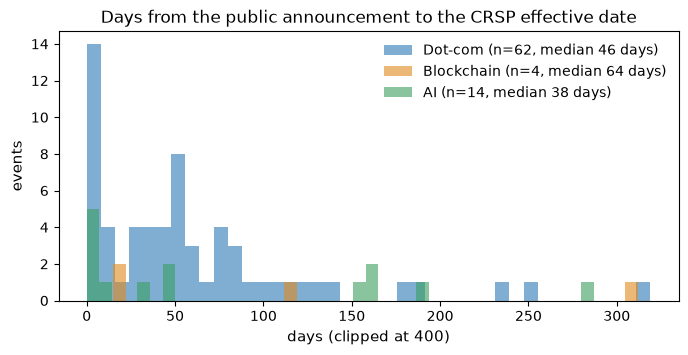

In [17]:
graded = register[register["date_confidence"].isin(["A", "B"])].copy()
graded["days_to_effective"] = (graded["effective_date"] - graded["public_announcement_date"]).dt.days
fig, ax = plt.subplots(figsize=(8, 3.5))
for theme in themes:
    gaps = graded.loc[graded["theme"] == theme, "days_to_effective"]
    ax.hist(gaps.clip(upper=400), bins=40, alpha=0.6, color=theme_colors[theme],
            label=f"{theme} (n={len(gaps)}, median {gaps.median():.0f} days)")
ax.set(title="Days from the public announcement to the CRSP effective date",
       xlabel="days (clipped at 400)", ylabel="events")
ax.legend(frameon=False)
plt.show()

## Step 8: Daily stock data and processed files
The event firms' daily CRSP data are in `data/raw_data/wrds/crsp_daily_event_firms.csv.gz`; we check that
the file covers every event firm. The processed tables used by notebook 03 are then saved: events with the
`event_date` (Step 7b), listed firms per year, all name changes, and the identifier checks.

In [18]:
daily_file = wrds_dir / "crsp_daily_event_firms.csv.gz"
needed = set(events["permno"].unique())
have = set(pd.read_csv(daily_file, usecols=["permno"])["permno"])
print("daily stock file covers all event PERMNOs:", needed <= have)

daily stock file covers all event PERMNOs: True


In [19]:
register_to_events = ["event_id", "event_date", "event_date_basis", "public_announcement_date", "date_confidence",
                      "announcement_timing", "deal_type", "in_wave_period", "in_wave_effective_year", "primary_sample",
                      "needs_second_check", "earliest_recorded_date"]
events_final = events.drop(columns="in_wave_period").merge(register[register_to_events], on="event_id")
events_final["event_year"] = events_final["event_date"].dt.year
events_final.to_csv(processed_dir / "events.csv", index=False)
listed.to_csv(processed_dir / "listed_firms.csv", index=False)
all_changes.to_csv(processed_dir / "all_name_changes.csv", index=False)
excluded_events.to_csv(processed_dir / "events_excluded.csv", index=False)
identifier_checks.to_csv(processed_dir / "identifier_checks.csv", index=False)
print("saved:", sorted(p.name for p in processed_dir.iterdir()))

saved: ['all_name_changes.csv', 'announcement_events.csv', 'control_group_events.csv', 'events.csv', 'events_excluded.csv', 'identifier_checks.csv', 'listed_firms.csv']
